# Taller Final – Minería de Datos
## Segmentación de clientes con K-Means (Mall Customers Dataset)

**Objetivo general:** desarrollar un modelo de segmentación de clientes con K-Means, evaluado con el método del codo y el coeficiente de silueta, para analizar patrones de comportamiento y apoyar decisiones de marketing.

Contenido:
1. Exploración de datos
2. Preprocesamiento
3. Método del codo
4. Coeficiente de silueta
5. Modelo K-Means
6. Interpretación de negocio
7. Despliegue con Streamlit (archivo `app.py`)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import joblib
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Parte 1 – Exploración de datos
### 1.1 Cargar el dataset

In [2]:
df = pd.read_csv("../datos/raw/Mall_Customers.csv")
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()
print("\nValores nulos por columna:")
print(df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

Valores nulos por columna:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Filas duplicadas: 0


### 1.2 Identificar variables relevantes

In [4]:
# CustomerID es solo un identificador: no aporta información de comportamiento
print(df.columns.tolist())
print("\nDistribución por género:")
print(df["Gender"].value_counts())

['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Distribución por género:
Gender
Female    112
Male       88
Name: count, dtype: int64


### 1.3 Análisis descriptivo básico

In [5]:
num_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
df[num_cols].describe().round(2)

,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


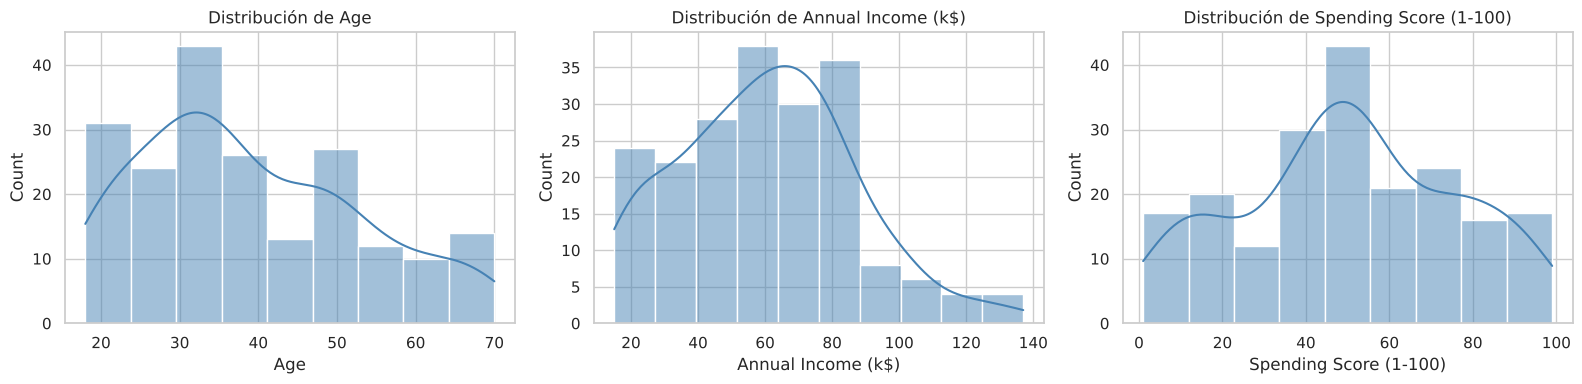

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribución de {col}")
plt.tight_layout(); plt.show()

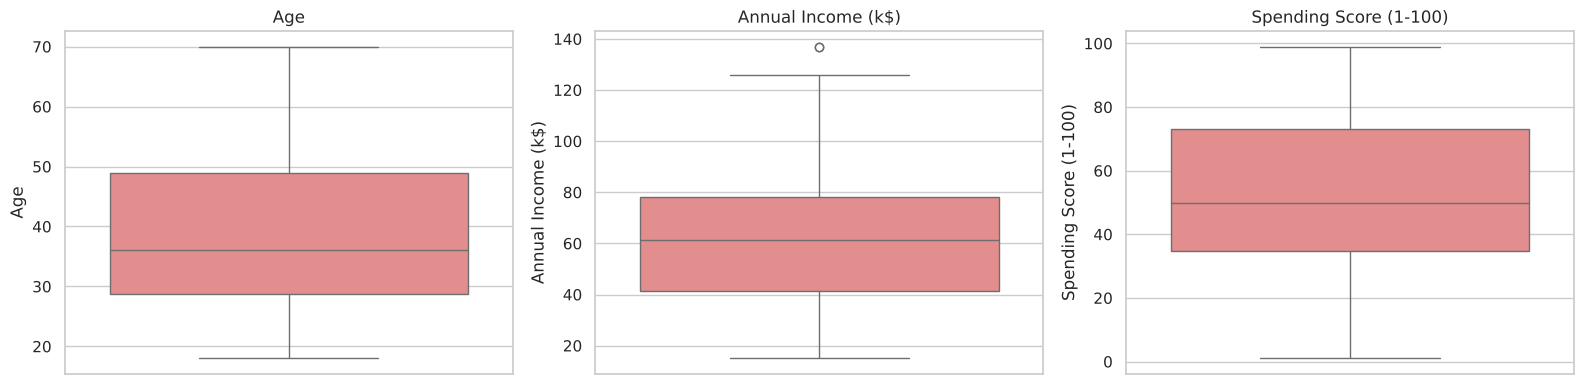

Age: 0 atípicos (límites -1.62 – 79.38)
Annual Income (k$): 2 atípicos (límites -13.25 – 132.75)
 CustomerID  Annual Income (k$)
        199                 137
        200                 137
Spending Score (1-100): 0 atípicos (límites -22.62 – 130.38)


In [7]:
# Boxplots para detectar valores atípicos
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="lightcoral")
    ax.set_title(col)
plt.tight_layout(); plt.show()

# Detección de atípicos con el criterio IQR
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    atip = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    print(f"{col}: {len(atip)} atípicos (límites {lim_inf:.2f} – {lim_sup:.2f})")
    if len(atip):
        print(atip[["CustomerID", col]].to_string(index=False))

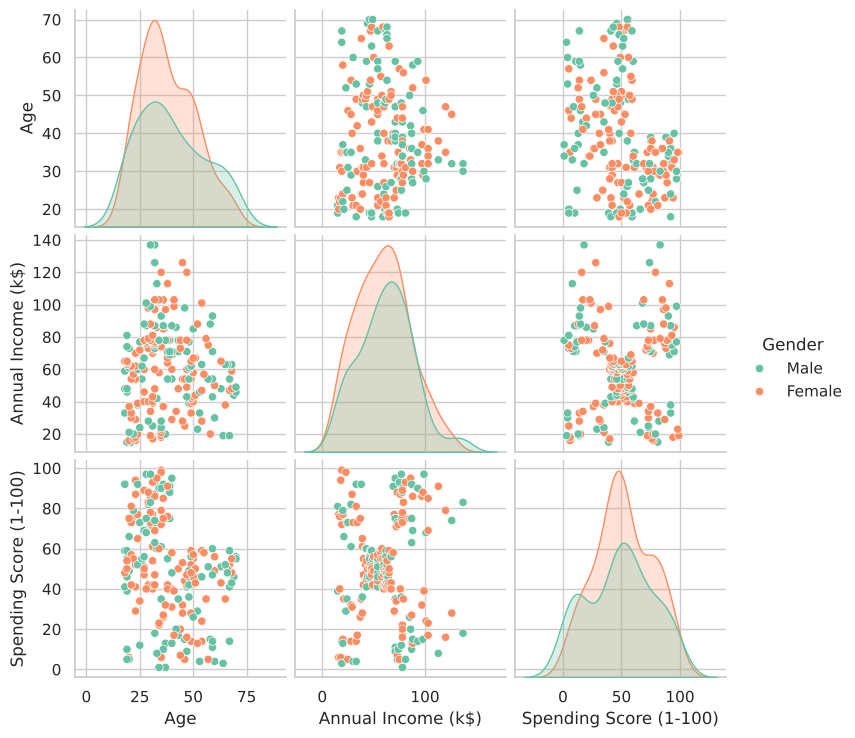

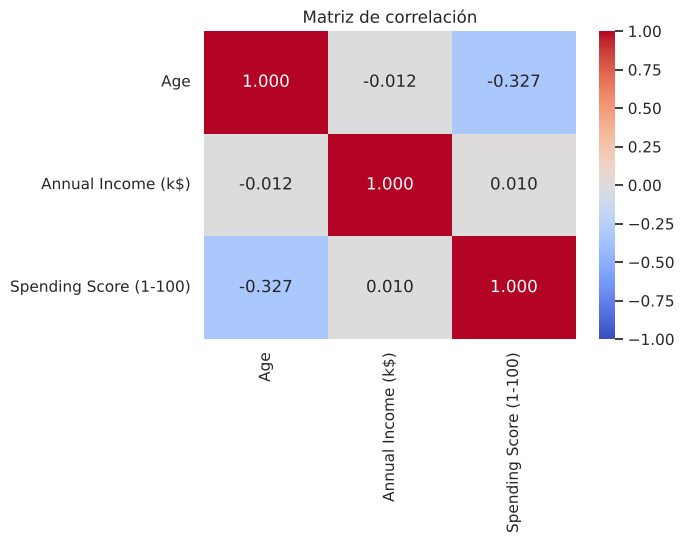

In [8]:
# Relaciones entre variables
sns.pairplot(df, vars=num_cols, hue="Gender", diag_kind="kde", palette="Set2")
plt.show()

plt.figure(figsize=(6, 4))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.show()

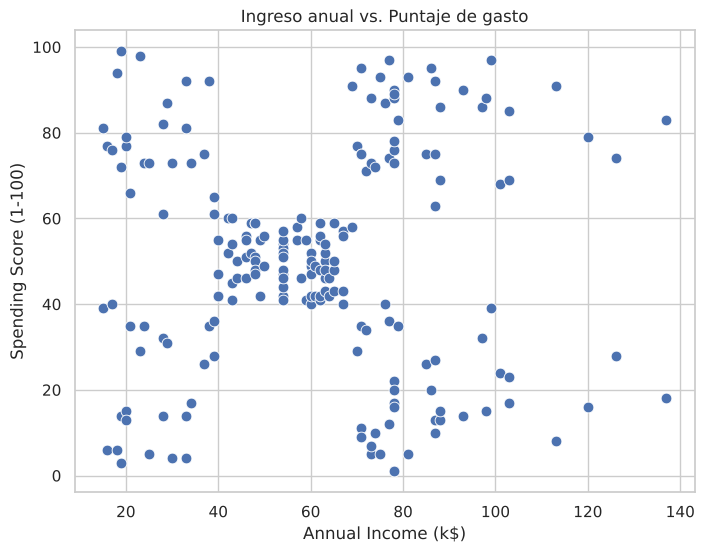

In [9]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", s=60)
plt.title("Ingreso anual vs. Puntaje de gasto")
plt.show()

### Preguntas – Parte 1

**¿Qué variables son más adecuadas para segmentar clientes?**

`Annual Income (k$)` y `Spending Score (1-100)`. Juntas describen la **capacidad de compra** y el **comportamiento de compra** del cliente, que es justo lo que interesa a marketing. Además, en el diagrama de dispersión ingreso vs. gasto se ven a simple vista unos 5 grupos bien separados, cosa que no ocurre con las demás combinaciones.

- `CustomerID` se descarta porque es un identificador sin significado.
- `Gender` es categórica; K-Means trabaja con distancias euclidianas y no maneja bien variables binarias. Además, la distribución de ingreso y gasto es muy parecida entre hombres y mujeres (ver pairplot).
- `Age` es útil para **describir** los segmentos después (perfilamiento), pero al incluirla los grupos se separan peor. Por eso se usa como variable descriptiva y no de agrupamiento.

**¿Se identifican valores atípicos?**

Con el criterio IQR (1.5 × rango intercuartílico):
- `Age` y `Spending Score`: **no** hay atípicos.
- `Annual Income`: solo **2 clientes** (ID 199 y 200, con 137 k$) superan el límite superior de 132.75 k$.

Son valores levemente por encima del límite y plausibles (clientes de ingreso muy alto), no errores de captura. Se **conservan**, porque eliminarlos haría perder justamente a clientes de alto ingreso, relevantes para el negocio. Tampoco hay nulos ni duplicados.

**¿Qué tipo de relaciones se observan entre las variables?**

- Ingreso vs. gasto: correlación prácticamente **nula (≈ 0.01)**. Tener más ingreso no implica gastar más; por eso es interesante segmentar: hay clientes ricos que gastan poco y clientes de bajo ingreso que gastan mucho. La relación no es lineal sino **por grupos** (forma de "X" o cinco nubes).
- Edad vs. gasto: correlación **negativa moderada (≈ −0.33)**: los clientes jóvenes tienden a tener mayor puntaje de gasto; los mayores de ~40 años rara vez superan 60 puntos.
- Edad vs. ingreso: sin relación lineal (≈ −0.01).

# Parte 2 – Preprocesamiento

In [10]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Medias originales:", X.mean(axis=0).round(2))
print("Desv. originales :", X.std(axis=0).round(2))
print("Medias escaladas :", X_scaled.mean(axis=0).round(4))
print("Desv. escaladas  :", X_scaled.std(axis=0).round(4))
pd.DataFrame(X_scaled, columns=features).head()

Medias originales: [60.56 50.2 ]
Desv. originales : [26.2  25.76]
Medias escaladas : [-0. -0.]
Desv. escaladas  : [1. 1.]


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


### Pregunta – Parte 2

**¿Por qué es necesario escalar las variables en el algoritmo K-Means?**

K-Means asigna cada punto al centroide más cercano usando la **distancia euclidiana**. Si las variables están en escalas distintas, la de mayor rango domina la distancia y el algoritmo prácticamente ignora las demás. Por ejemplo, el ingreso va de 15 a 137 y la edad de 18 a 70: sin escalar, una diferencia de 20 k$ "pesaría" lo mismo que 20 años, aunque no signifiquen lo mismo.

`StandardScaler` transforma cada variable a **media 0 y desviación 1** (z = (x − μ)/σ), de modo que todas contribuyen por igual a la distancia. Esto hace que los clusters reflejen la estructura real de los datos y no las unidades de medida. En este dataset ingreso y gasto tienen rangos parecidos, pero escalar sigue siendo buena práctica y es indispensable si se agrega otra variable (como la edad).

# Parte 3 – Método del codo

In [11]:
K_range = range(1, 11)
inercias = []
for k in K_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(X_scaled)
    inercias.append(km.inertia_)

pd.DataFrame({"K": list(K_range), "Inercia (WCSS)": np.round(inercias, 2)})

,K,Inercia (WCSS)
0,1,400.00
1,2,269.69
2,3,157.70
3,4,108.92
4,5,65.57
5,6,55.06
6,7,44.86
7,8,37.23
8,9,32.39
9,10,29.98


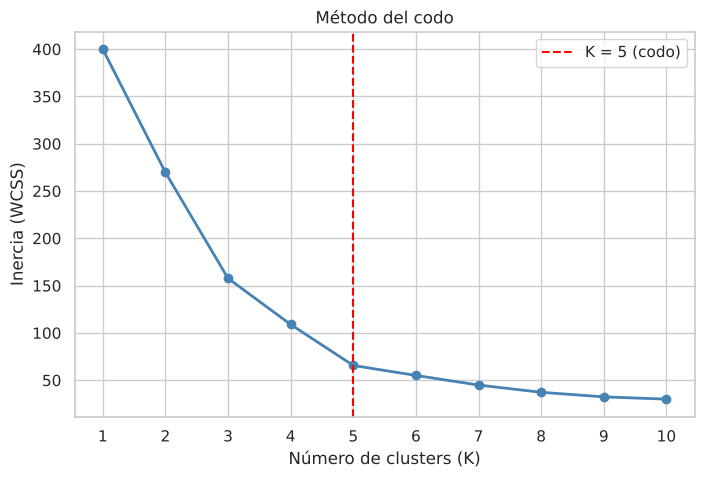

,K,Reducción % respecto a K-1
0,1,NaN
1,2,32.6
2,3,41.5
3,4,30.9
4,5,39.8
5,6,16.0
6,7,18.5
7,8,17.0
8,9,13.0
9,10,7.4


In [12]:
plt.figure(figsize=(8, 5))
plt.plot(K_range, inercias, "o-", color="steelblue", linewidth=2)
plt.axvline(5, color="red", linestyle="--", label="K = 5 (codo)")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia (WCSS)")
plt.title("Método del codo")
plt.xticks(K_range)
plt.legend()
plt.show()

# Reducción porcentual de la inercia al pasar de K-1 a K
red = [None] + [round((inercias[i-1] - inercias[i]) / inercias[i-1] * 100, 1) for i in range(1, len(inercias))]
pd.DataFrame({"K": list(K_range), "Reducción % respecto a K-1": red})

### Preguntas – Parte 3

**¿Por qué valores cercanos a cero indican mejor ajuste?**

La inercia (WCSS, *Within-Cluster Sum of Squares*) es la suma de las distancias al cuadrado de cada punto a su centroide:

$$WCSS = \sum_{j=1}^{K} \sum_{x_i \in C_j} \lVert x_i - \mu_j \rVert^2$$

Si es cercana a cero, los puntos están muy pegados a su centroide, es decir, los clusters son **compactos y homogéneos**: los clientes de un mismo grupo se parecen mucho entre sí.

Ojo: la inercia **siempre baja** al aumentar K, y llega a 0 cuando K = n (cada cliente es su propio cluster), lo cual no sirve para nada. Por eso no se busca el K con inercia mínima, sino el punto donde agregar más clusters deja de mejorar significativamente.

**¿Cómo se identifica el punto óptimo de K?**

Se busca el **"codo"** de la curva: el punto a partir del cual la inercia deja de caer bruscamente y la curva se aplana. Antes del codo, cada cluster adicional reduce mucho la inercia; después, la ganancia es marginal y solo se están partiendo grupos que ya eran coherentes.

En esta gráfica el codo está en **K = 5**: de K = 4 a K = 5 la inercia cae de ≈109 a ≈66 (≈40 %), pero de K = 5 a K = 6 solo baja de ≈66 a ≈55 (≈16 %), y de ahí en adelante las reducciones son pequeñas.

# Parte 4 – Coeficiente de silueta

In [13]:
K_sil = range(2, 11)   # la silueta no está definida para K = 1
siluetas = []
for k in K_sil:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    siluetas.append(silhouette_score(X_scaled, labels))

tabla_sil = pd.DataFrame({"K": list(K_sil), "Silueta": np.round(siluetas, 4)})
k_opt = tabla_sil.loc[tabla_sil["Silueta"].idxmax(), "K"]
print("K con mayor silueta:", k_opt)
tabla_sil

K con mayor silueta: 5


,K,Silueta
0,2,0.3213
1,3,0.4666
2,4,0.4939
3,5,0.5547
4,6,0.5399
5,7,0.5281
6,8,0.4552
7,9,0.4571
8,10,0.4432


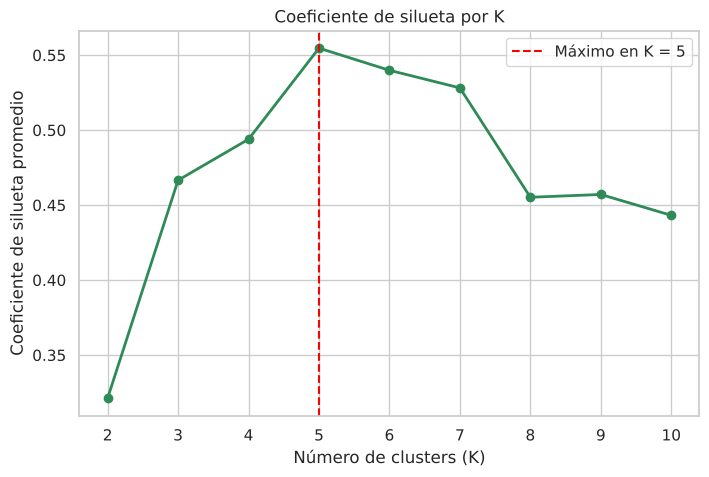

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(K_sil, siluetas, "o-", color="seagreen", linewidth=2)
plt.axvline(k_opt, color="red", linestyle="--", label=f"Máximo en K = {k_opt}")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Coeficiente de silueta promedio")
plt.title("Coeficiente de silueta por K")
plt.xticks(list(K_sil))
plt.legend()
plt.show()

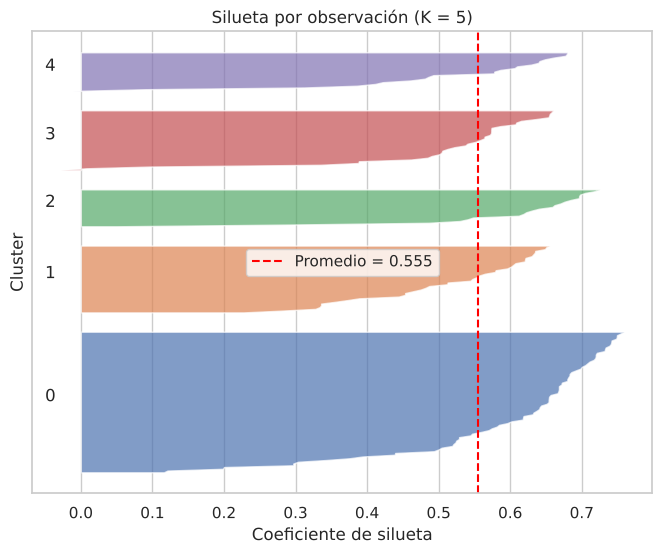

Observaciones con silueta negativa: 2


In [15]:
# Gráfico de silueta por observación para K = 5
from sklearn.metrics import silhouette_samples
km5 = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X_scaled)
sil_vals = silhouette_samples(X_scaled, km5.labels_)

fig, ax = plt.subplots(figsize=(8, 6))
y_low = 10
for c in range(5):
    vals = np.sort(sil_vals[km5.labels_ == c])
    ax.fill_betweenx(np.arange(y_low, y_low + len(vals)), 0, vals, alpha=0.7)
    ax.text(-0.05, y_low + len(vals) / 2, str(c))
    y_low += len(vals) + 10
ax.axvline(sil_vals.mean(), color="red", linestyle="--", label=f"Promedio = {sil_vals.mean():.3f}")
ax.set_xlabel("Coeficiente de silueta"); ax.set_ylabel("Cluster")
ax.set_title("Silueta por observación (K = 5)"); ax.legend(); ax.set_yticks([])
plt.show()
print("Observaciones con silueta negativa:", (sil_vals < 0).sum())

### Preguntas – Parte 4

**¿Qué mide el coeficiente de silueta?**

Mide qué tan bien asignado está cada punto a su cluster, combinando **cohesión** (qué tan cerca está de los de su grupo) y **separación** (qué tan lejos está del grupo vecino más cercano):

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}$$

- $a(i)$: distancia promedio del punto $i$ a los demás puntos de su propio cluster.
- $b(i)$: distancia promedio del punto $i$ a los puntos del cluster vecino más cercano.

Toma valores entre −1 y 1. El coeficiente del modelo es el promedio de $s(i)$ sobre todos los puntos.

**¿Qué significa un valor cercano a 1?**

Que $a(i) \ll b(i)$: el punto está muy cerca de los de su grupo y lejos de los otros grupos. Los clusters son **compactos y bien separados**; la asignación es clara.

**¿Qué implica un valor cercano a 0 o negativo?**

- **Cercano a 0:** $a(i) \approx b(i)$; el punto está en la **frontera** entre dos clusters, los grupos se solapan y la asignación es ambigua.
- **Negativo:** $a(i) > b(i)$; el punto está más cerca, en promedio, de otro cluster que del suyo, es decir, probablemente está **mal asignado**. Un promedio negativo indicaría una mala segmentación.

**¿Coincide el valor óptimo de K con el método del codo? Justifique.**

**Sí.** El método del codo señala **K = 5** y la silueta alcanza su **máximo también en K = 5 (≈ 0.555)**, por encima de K = 4 (≈ 0.494) y K = 6 (≈ 0.540). Ambos criterios apuntan al mismo valor por razones complementarias: el codo indica que con 5 grupos ya se captura casi toda la reducción de dispersión interna, y la silueta confirma que con 5 grupos los clusters están mejor separados que con cualquier otro K. Un valor de 0.55 indica una estructura de clusters razonablemente fuerte. Esto coincide además con las 5 nubes de puntos visibles en el diagrama de dispersión de la Parte 1. **Se selecciona K = 5.**

# Parte 5 – Modelo K-Means

In [16]:
K = 5
kmeans = KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Inercia final:", round(kmeans.inertia_, 2))
print("Silueta final:", round(silhouette_score(X_scaled, df["Cluster"]), 4))
df.head(10)

Inercia final: 65.57
Silueta final: 0.5547


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


In [17]:
# Centroides en escala estandarizada y en escala original
centroides_esc = pd.DataFrame(kmeans.cluster_centers_, columns=features)
centroides = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features).round(2)
centroides.index.name = "Cluster"
print("Centroides (escala estandarizada):")
print(centroides_esc.round(3))
print("\nCentroides (escala original):")
centroides

Centroides (escala estandarizada):
   Annual Income (k$)  Spending Score (1-100)
0              -0.201                  -0.026
1               0.992                   1.240
2              -1.330                   1.132
3               1.055                  -1.284
4              -1.308                  -1.137

Centroides (escala original):


,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


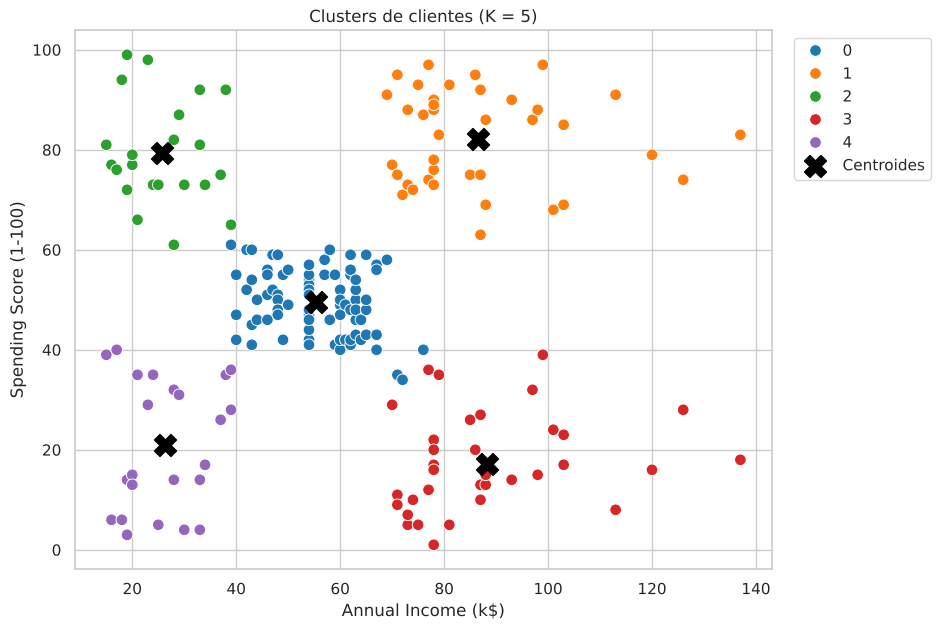

In [18]:
plt.figure(figsize=(9, 7))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="Cluster", palette="tab10", s=70)
plt.scatter(centroides.iloc[:, 0], centroides.iloc[:, 1], c="black", s=250, marker="X", label="Centroides")
plt.title("Clusters de clientes (K = 5)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

In [19]:
# Perfil de cada cluster (incluyendo edad y género como variables descriptivas)
perfil = df.groupby("Cluster").agg(
    Clientes=("CustomerID", "count"),
    Edad_media=("Age", "mean"),
    Ingreso_medio=("Annual Income (k$)", "mean"),
    Gasto_medio=("Spending Score (1-100)", "mean"),
    Pct_mujeres=("Gender", lambda g: (g == "Female").mean() * 100),
).round(1)
perfil["Pct_clientes"] = (perfil["Clientes"] / len(df) * 100).round(1)
perfil

,Clientes,Edad_media,Ingreso_medio,Gasto_medio,Pct_mujeres,Pct_clientes
Cluster,,,,,,
0,81,42.7,55.3,49.5,59.3,40.5
1,39,32.7,86.5,82.1,53.8,19.5
2,22,25.3,25.7,79.4,59.1,11.0
3,35,41.1,88.2,17.1,45.7,17.5
4,23,45.2,26.3,20.9,60.9,11.5


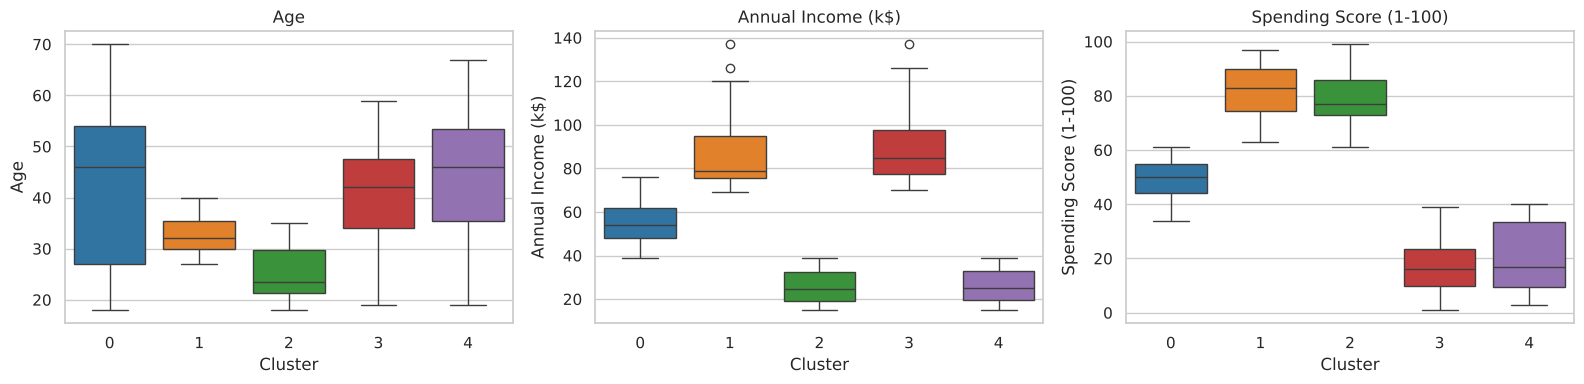

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Cluster", y=col, palette="tab10", ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

### Preguntas – Parte 5

**¿Qué representa cada cluster?**

Cada cluster es un grupo de clientes con un **comportamiento de compra similar** en términos de ingreso y gasto; su centroide es el "cliente típico" del grupo. Según los centroides (los números de cluster pueden variar de orden, pero los grupos son los mismos):

| Grupo | Ingreso medio | Gasto medio | Edad media | Clientes | Descripción |
|---|---|---|---|---|---|
| Ingreso alto – gasto alto | ≈ 87 k$ | ≈ 82 | ≈ 33 | 39 (19.5 %) | Clientes jóvenes-adultos con alto poder adquisitivo que compran mucho |
| Ingreso alto – gasto bajo | ≈ 88 k$ | ≈ 17 | ≈ 41 | 35 (17.5 %) | Tienen dinero pero gastan poco en el centro comercial |
| Ingreso medio – gasto medio | ≈ 55 k$ | ≈ 50 | ≈ 43 | 81 (40.5 %) | El grupo más grande; comportamiento "promedio" |
| Ingreso bajo – gasto alto | ≈ 26 k$ | ≈ 79 | ≈ 25 | 22 (11 %) | Los más jóvenes; gastan mucho en relación con lo que ganan |
| Ingreso bajo – gasto bajo | ≈ 26 k$ | ≈ 21 | ≈ 45 | 23 (11.5 %) | Bajo ingreso y compras moderadas/escasas |

**¿Qué diferencias existen entre los grupos obtenidos?**

- **Ingreso:** separa los clusters en tres franjas: bajo (~26 k$), medio (~55 k$) y alto (~87 k$).
- **Gasto:** dentro de las franjas de ingreso bajo y alto hay dos comportamientos opuestos (gasto ~20 vs. ~80), lo que confirma que el ingreso por sí solo no predice el gasto.
- **Edad (variable no usada en el modelo):** los grupos de gasto alto son claramente más jóvenes (25–33 años) que los de gasto bajo (41–45 años), coherente con la correlación negativa edad–gasto de la Parte 1.
- **Tamaño:** el grupo medio concentra el 40 % de los clientes; los otros cuatro tienen entre el 11 % y el 20 %.
- **Dispersión:** los boxplots muestran que los grupos de ingreso medio son los más compactos, mientras que los de ingreso alto tienen mayor variabilidad en ingreso.

# Parte 6 – Interpretación de negocio

In [21]:
def nombrar_perfil(ingreso, gasto):
    """Asigna un perfil de negocio a partir del centroide (escala original)."""
    if ingreso >= 70 and gasto >= 60:
        return "Alto valor"
    if ingreso >= 70 and gasto < 40:
        return "Con potencial"
    if ingreso < 40 and gasto < 40:
        return "Bajo valor"
    if ingreso < 40 and gasto >= 60:
        return "Gastadores impulsivos"
    return "Promedio"

mapa_perfiles = {c: nombrar_perfil(r.iloc[0], r.iloc[1]) for c, r in centroides.iterrows()}
df["Perfil"] = df["Cluster"].map(mapa_perfiles)
print(mapa_perfiles)

resumen = perfil.copy()
resumen.insert(0, "Perfil", resumen.index.map(mapa_perfiles))
resumen.sort_values("Ingreso_medio", ascending=False)

{0: 'Promedio', 1: 'Alto valor', 2: 'Gastadores impulsivos', 3: 'Con potencial', 4: 'Bajo valor'}


,Perfil,Clientes,Edad_media,Ingreso_medio,Gasto_medio,Pct_mujeres,Pct_clientes
Cluster,,,,,,,
3,Con potencial,35,41.1,88.2,17.1,45.7,17.5
1,Alto valor,39,32.7,86.5,82.1,53.8,19.5
0,Promedio,81,42.7,55.3,49.5,59.3,40.5
4,Bajo valor,23,45.2,26.3,20.9,60.9,11.5
2,Gastadores impulsivos,22,25.3,25.7,79.4,59.1,11.0


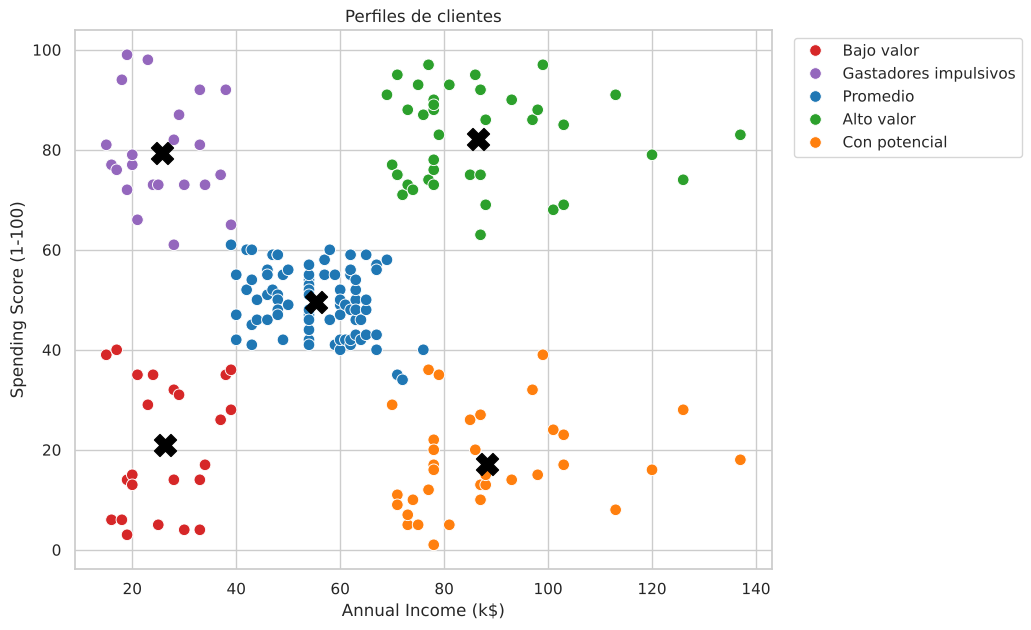

In [22]:
colores = {"Alto valor": "#2ca02c", "Con potencial": "#ff7f0e", "Promedio": "#1f77b4",
           "Gastadores impulsivos": "#9467bd", "Bajo valor": "#d62728"}
plt.figure(figsize=(9, 7))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="Perfil", palette=colores, s=70)
plt.scatter(centroides.iloc[:, 0], centroides.iloc[:, 1], c="black", s=250, marker="X")
plt.title("Perfiles de clientes")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

### Clasificación de los clusters en perfiles

| Perfil | Centroide (ingreso, gasto) | Justificación |
|---|---|---|
| **Clientes de alto valor** | (≈ 87, ≈ 82) | Alto ingreso y alto gasto: los que más dinero dejan |
| **Clientes con potencial** | (≈ 88, ≈ 17) | Mismo ingreso que los de alto valor, pero gastan muy poco: tienen capacidad de compra sin aprovechar |
| **Clientes promedio** | (≈ 55, ≈ 50) | Valores medios en ambas variables; grupo más grande |
| **Clientes de bajo valor** | (≈ 26, ≈ 21) | Bajo ingreso y bajo gasto |
| **Gastadores impulsivos** (5.º grupo) | (≈ 26, ≈ 79) | Bajo ingreso pero gasto alto; como el modelo encontró 5 grupos, se agrega este perfil, ya que no encaja en los cuatro sugeridos |

### Preguntas – Parte 6

**¿Qué estrategias de marketing se podrían aplicar a cada grupo?**

- **Alto valor:** fidelización y retención. Programa VIP o de membresía premium, acceso anticipado a lanzamientos, atención personalizada, eventos exclusivos y marcas de lujo. El objetivo es que no se vayan a la competencia.
- **Con potencial:** activación. Investigar por qué gastan poco (¿no encuentran lo que buscan?, ¿compran en otro lugar?). Ofrecer productos de mayor calidad y valor, experiencias (restaurantes, entretenimiento), campañas personalizadas por sus intereses y beneficios por primera compra en tiendas premium. Este grupo suele ser más maduro y racional en sus compras, así que conviene comunicar calidad y valor más que descuentos.
- **Promedio:** mantener y aumentar el ticket. Programas de puntos, venta cruzada (*cross-selling*), promociones por temporada y combos. Al ser el grupo más numeroso, pequeñas mejoras en su gasto generan un gran impacto total.
- **Bajo valor:** estrategias de bajo costo. Descuentos, ofertas de precio, productos básicos y comunicación masiva por canales económicos. No conviene invertir mucho presupuesto de marketing aquí.
- **Gastadores impulsivos:** jóvenes que gastan mucho. Promociones en redes sociales, tendencias y moda, opciones de pago en cuotas o "compra ahora, paga después" y programas de recompensa para mantener la frecuencia. Hay que cuidar el riesgo crediticio y apostar por la lealtad a largo plazo, pues su ingreso probablemente crecerá con la edad.

**¿Qué segmento representa mayor oportunidad de crecimiento?**

Los **clientes con potencial (ingreso alto – gasto bajo)**. Tienen prácticamente el mismo ingreso que los clientes de alto valor (~88 k$), pero un puntaje de gasto de solo ~17 frente a ~82. Es decir, el dinero existe pero no se está gastando en el centro comercial. Son 35 clientes (17.5 %), un grupo de tamaño considerable. Si una estrategia de activación lograra subir su gasto aunque sea a nivel promedio, el aumento de ingresos sería mayor que en cualquier otro segmento, porque los de alto valor ya están cerca del máximo y los de bajo ingreso tienen un techo limitado por su capacidad de compra.

> **Exportación del modelo:** en este proyecto el entrenamiento final, la limpieza del dataset, la exportación del modelo (`modelo/kmeans_model.joblib` y `modelo/scaler.joblib`) y el guardado de las imágenes los hace el script **`backend/train.py`**, que repite este mismo proceso de forma automática.

# Parte 7 – Despliegue con Streamlit

La aplicación está en **`frontend/app.py`**. Carga el modelo exportado por el backend y permite:
- Visualizar el método del codo (y el coeficiente de silueta)
- Mostrar los clusters generados y sus perfiles
- Ingresar un nuevo cliente
- Clasificarlo automáticamente en un cluster y ver su perfil y la estrategia sugerida

**Cómo ejecutarla** (desde la carpeta raíz del proyecto):

```bash
pip install -r requirements.txt
python backend/train.py
streamlit run frontend/app.py
```

In [23]:
# Prueba rápida de la lógica de clasificación que usa la app
nuevo = pd.DataFrame([[90, 20]], columns=features)  # ingreso 90 k$, gasto 20
c = kmeans.predict(scaler.transform(nuevo.values))[0]
print(f"Cluster asignado: {c} → Perfil: {mapa_perfiles[c]}")

Cluster asignado: 3 → Perfil: Con potencial


# Conclusiones

1. Las variables más útiles para segmentar fueron ingreso anual y puntaje de gasto; los datos no tenían nulos y solo 2 atípicos leves que se conservaron.
2. El escalado con `StandardScaler` garantiza que ambas variables pesen igual en la distancia euclidiana.
3. El método del codo y el coeficiente de silueta coinciden en **K = 5** (silueta ≈ 0.55), lo que da confianza en la elección.
4. Los cinco segmentos tienen interpretación clara de negocio: alto valor, con potencial, promedio, bajo valor y gastadores impulsivos.
5. El segmento con mayor oportunidad de crecimiento es el de **ingreso alto y gasto bajo**.
6. El modelo se desplegó en una app de Streamlit que clasifica nuevos clientes en tiempo real.